# MOSH vs new UCSF applicator

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for UCSF plots
z_slice_ucsf = 25
bins_ucsf = 75
dose_grid_half_ucsf = 2.55
lattice_ucsf = dose_grid_half_ucsf*2/bins_ucsf
source_transZ_ucsf = -0.5
source_plane_ucsf = cm_to_voxel(np.array(source_transZ_ucsf), bins_ucsf, dose_grid_half_ucsf*2/bins_ucsf)

In [4]:
# Set parameters for MOSH plots
z_slice_mosh = 25
bins_mosh = 85
dose_grid_half_mosh = 2.5
lattice_mosh = dose_grid_half_mosh*2/bins_mosh
source_transZ_mosh = -0.5
source_plane_mosh = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, dose_grid_half_mosh*2/bins_mosh)

In [5]:
# Common parameters
norm_point = (0.0, 0.3)
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

## Comparison - basic architecture

What do we want to compare? Values that we care about include:

    - Mucosal dose of each applicator, defined as dose delivered at edge of applicator (just outside r = 0.3 cm)
    - Dose delivered to ROI
    - Dose delivered everywhere except the ROI (initially, will include the mucosal dose)

To compare these values between MOSH and UCSF:

    - Sum of dose delivered in each region (e.g. sum all voxels in a given region) and make direct comparison
    - Plot dose at constant angle (for ROI) or constant radius (for mucosal dose)
    - Subtract doses and produce contour plot of difference to observe "hotspots"
    - Others?

## Comparison - single ROI to "north" of position 1

In [6]:
# Step 1: define ROI
# Simple ROI = cubical region centered @ 0.5 cm from edge of applicator, 0.2 cm to each side
# Units = cm
x0 = -0.1
x1 = 0.1
y0 = 0.40
y1 = 0.60
roi_side = 0.2

roi = np.array([x0, x1, y0, y1])

# Convert ROI definition to voxel space - UCSF
roi_vox_ucsf = cm_to_voxel(roi, bins_ucsf, lattice_ucsf)
print(roi_vox_ucsf)

# Convert ROI definition to voxel space - UCSF
roi_vox_mosh = cm_to_voxel(roi, bins_mosh, lattice_mosh)
print(roi_vox_mosh)

[36 38 43 46]
[40 44 49 52]


In [7]:
# Step 2: load each applicator distribution
# UCSF
ucsf = "/Users/seanmullane/Desktop/Research_2023/Sept_outputs/removed23_1e7_75bins_2.55cmHL.csv"

norm_energy, __ = extract_norm_energy(ucsf, source_plane_ucsf, 2, norm_point, bins_ucsf, lattice_ucsf)

Xu, Yu, energyu, __ = contour_energy(ucsf, (bins_ucsf, bins_ucsf), dose_grid_half_ucsf, source_plane_ucsf, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=False, norm_energy=norm_energy, zero_source=True, std_dev=False)

In [8]:
# MOSH - use same norm energy as UCSF!
mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

Xm, Ym, energym, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=False, norm_energy=norm_energy, zero_source=True, std_dev=False)

In [9]:
# Extract dose in ROI for each applicator
# UCSF
roi_dose_ucsf = energyu[roi_vox_ucsf[0]:roi_vox_ucsf[1], roi_vox_ucsf[2]:roi_vox_ucsf[3]]
print(np.shape(roi_dose_ucsf))

# MOSH
roi_dose_mosh = energym[roi_vox_mosh[0]:roi_vox_mosh[1], roi_vox_mosh[2]:roi_vox_mosh[3]]
print(np.shape(roi_dose_mosh))

(2, 3)
(4, 3)


In [10]:
# Compare total dose delivered to ROI for each applicator
total_dose_ucsf = np.sum(roi_dose_ucsf)
print("UCSF: " + str(total_dose_ucsf))

total_dose_mosh = np.sum(roi_dose_mosh)
print("MOSH: " + str(total_dose_mosh))

UCSF: 1.891086755632607e-14
MOSH: 7.390754284131162e-07


There is a 7 order-of-magnitude difference between dose delivered by MOSH and dose delivered by USCF! However, note that the simulations used slightly different bin and lattice parameters, so to get a more accurate comparison we should re-run sims with those values matching.

Let's plot the UCSF and MOSH distributions with the ROI shown on each plot.

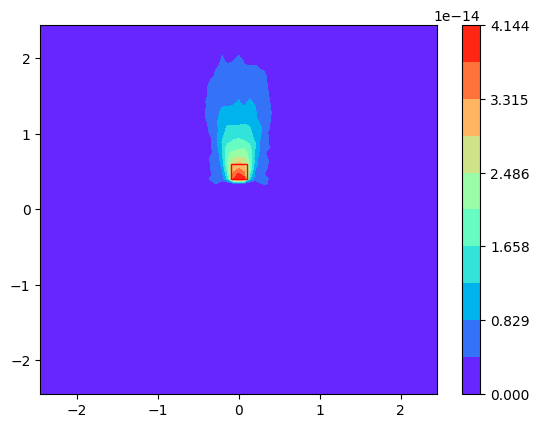

In [11]:
# Plotting UCSF
figu, axu = plt.subplots()
contouru = axu.contourf(Xu, Yu, energyu, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
axu.add_patch(region)

cbaru = figu.colorbar(contouru)

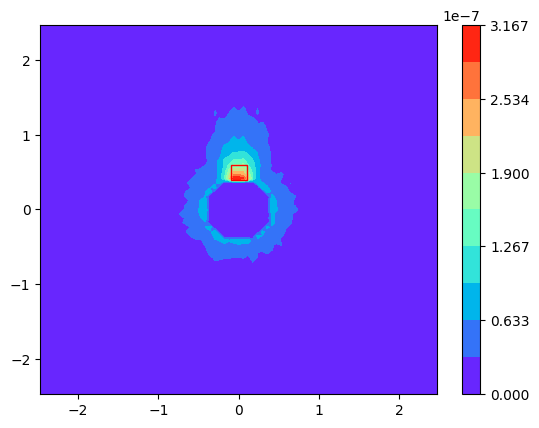

In [12]:
# Plotting MOSH
figm, axm = plt.subplots()
contourm = axm.contourf(Xm, Ym, energym, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
axm.add_patch(region)

cbarm = figm.colorbar(contourm)

Next, we'll extract the energy along a constant-angle line to the center of the ROI.

In [21]:
# Define center of ROI
roi_center = (x0 + roi_side/2, y0 + roi_side/2)

# Compute angle from origin to roi_center
theta = np.arctan2(roi_center[1], roi_center[0])
print(theta) # pi/2, as expected for this example

# Compute distance from origin to roi_center
roi_rad = np.sqrt(roi_center[0]**2 + roi_center[1]**2)

1.5707963267948966


In [36]:
# Extract energy along theta = pi/2 
# UCSF
lin_ucsf, const_rad_ucsf = energy_along_theta(ucsf, theta, (bins_ucsf, bins_ucsf), dose_grid_half_ucsf, z_slice_ucsf, radius=applicator_rad + 0.05)

# MOSH
lin_mosh, const_rad_mosh = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, z_slice_mosh, radius=applicator_rad + 0.05)

# Extract arrays to plot dose as function of radius @ constant theta
# USCF
xu, yu, __, __, __ = plotter_1D(lin_ucsf, plot_rng=(0.3, 1.0))

# MOSH
xm, ym, __, __, __ = plotter_1D(lin_mosh, plot_rng=(0.3, 1.0))

(74, 4)


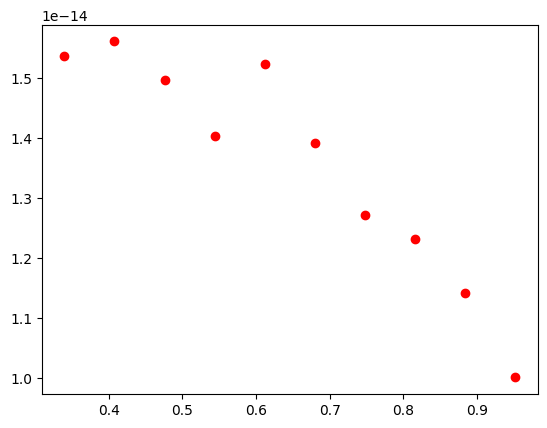

In [31]:
# Plot UCSF
fig1, ax1 = plt.subplots()
ax1.scatter(xu, yu, color="red")

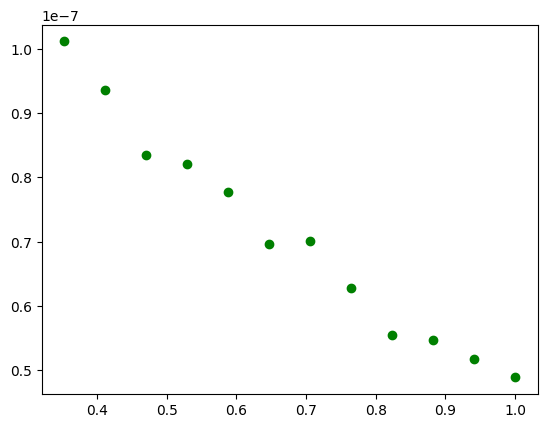

In [30]:
# Plot MOSH
fig2, ax2 = plt.subplots()
ax2.scatter(xm, ym, color="green")

Next, we'll compute the mucosal dose at r = 0.35 cm (just outside edge of applicator)

In [34]:
# Note that the data was already extracted when calling energy_along_theta above

# Extract arrays to plot dose as function of theta @ constant radius = 0.35 cm
# USCF
thetau, yu, __, __, __ = plotter_1D(const_rad_ucsf, ind_var=1)

# MOSH
thetam, ym, __, __, __ = plotter_1D(const_rad_mosh, ind_var=1)

ValueError: zero-size array to reduction operation minimum which has no identity